# QK-LSTM for climate time-series forecasting: does the quantum kernel help?

**Reproduction of** Hsu, N.-Y. Chen, T.-Y. Li, P.-H. Lee, K.-C. Chen, *Quantum Kernel-Based Long Short-term Memory for Climate Time-Series Forecasting*, [arXiv:2412.08851](https://arxiv.org/abs/2412.08851) (2024).

This notebook presents the reproduction as a scientific argument. It states the paper's claim, shows how to falsify it, runs a small live experiment, and then loads the full multi-seed evidence from stored run records to test the claim against fair baselines and controls.

| Section | Content |
|---|---|
| 1 | Problem statement and paper claim |
| 2 | Data, splits, metrics, evaluation protocol |
| 3 | The method in equations |
| 4 | Known-answer sanity checks |
| 5 | Model walkthrough |
| 6 | Small live experiment (smoke budget) |
| 7 | Headline reproduction result |
| 8 | Fair baseline comparison |
| 9 | Controls and ablations |
| 10 | Robustness and uncertainty |
| 11 | Photonic (MerLin) assessment |
| 12 | Claim-level conclusion |

**How to read the evidence.**
- The live cells (Sections 4–6, 11) recompute small things on your CPU in a few minutes.
- The headline numbers (Sections 7–11) are recomputed in this notebook from the stored structured artifacts (`metrics.json`, `run_status.json`) of 5-seed sweeps run with the same code (`lib/`), so every decisive number is derived here, not copied.

`README.md` and `LOG.md` hold the full record.

## 1. Problem statement and paper claim

**Task.** Forecast tomorrow's Air Quality Index (AQI) in Bengaluru from the last 3 days of 11 pollutant concentrations (CPCB data, 2015–2020).

**Method.** QK-LSTM keeps the LSTM recurrence but replaces each gate's linear map with a weighted sum of *quantum fidelity-kernel* values between the current input and a few reference vectors.

**The paper's claims** (single run per model):

| ID | Claim | Paper evidence |
|---|---|---|
| C1 | QK-LSTM beats a classical LSTM on RMSE, MAE, MAPE and R² | Table I: RMSE 9.20 vs 15.94, R² 0.84 vs 0.78 |
| C2 | ... with about 9× fewer trainable parameters | Table II: 209 vs 1,873 |
| C3 | QK-LSTM tracks the test period more faithfully | Fig. 3 (qualitative) |
| C4 | The gain comes from the quantum feature space | Argument only (Sec. III-B, V) |

**Falsifiable research question.**
> Under an identical data pipeline, training budget and evaluation protocol, with 5 seeds, does QK-LSTM achieve a lower test RMSE than (a) the paper's LSTM, (b) an LSTM with about the same number of parameters, and (c) the same QK-LSTM architecture with the quantum kernel replaced by a classical kernel?

**What would weaken the claims.**
- C1 and C2 are weakened if the paired, same-seed RMSE difference (QK-LSTM − baseline) has a 95% confidence interval that is not entirely below 0. They are *contradicted* if it lies entirely above 0.
- C4 is weakened if swapping the quantum kernel for a classical kernel changes RMSE by less than the seed-to-seed variability.

The decision rule was fixed before the comparison table was generated (`LOG.md`, *Phase 5 Comparison Plan*).

In [1]:
# Setup: paths, imports and a fixed colour convention used in every figure.
import json
import math
import statistics
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats

PROJECT_DIR = Path.cwd().resolve()
assert PROJECT_DIR.name == "QK_LSTM", f"Run this notebook from papers/QK_LSTM (cwd is {PROJECT_DIR})"
REPO_ROOT = PROJECT_DIR.parents[1]
for path in (REPO_ROOT, PROJECT_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from runtime_lib.config import load_config
from lib.data import build_dataloader, prepare_series

SWEEPS = PROJECT_DIR / "outdir" / "sweeps"
COLORS = {"quantum": "#2a78d6", "rbf": "#eb6834", "lstm": "#1baf7a", "photonic": "#eda100", "naive": "#6b6b66", "observed": "#2b2b29"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3de"})
print("torch", torch.__version__, "| numpy", np.__version__, "| repo", REPO_ROOT)

torch 2.12.1 | numpy 2.5.4 | repo /Users/martareina/Desktop/code/reproduced_papers


## 2. Data, splits, metrics and evaluation protocol

**Data.**
- File: `data/QK_LSTM/cpcb_aqi_india_2015_2020/city_day.csv`, the public Kaggle compilation of CPCB data (CC0).
- The paper cites only the CPCB portal. That this is the same data is *inferred* from the matching schema, time range and 11-feature set (Xylene is entirely missing for Bengaluru), not confirmed.

**Preprocessing** (paper Sec. II plus documented assumptions), all statistics fitted on **training days only**:
1. 11 pollutant inputs; target = next-day AQI; windows of 3 days.
2. Input values with |Z| > 3 are set to missing, then all columns are linearly interpolated in time.
3. Min-max scaling to [0, 1].

**Split.** Chronological 80/20 by target day. The paper's text says "2020 is the test set", but its Fig. 3 shows about 400 test days starting mid-2019, which matches 80/20 (402 days). The calendar-2020 split is used as a sensitivity check (Section 10).

**Metrics** (paper Eq. 20–23) are computed in AQI units **only on days whose AQI was actually observed**; interpolated targets are never scored:

$$\mathrm{RMSE}=\sqrt{\tfrac1N\sum(y_i-\hat y_i)^2},\quad \mathrm{MAE}=\tfrac1N\sum|y_i-\hat y_i|,\quad \mathrm{MAPE}=\tfrac{100}{N}\sum\left|\tfrac{y_i-\hat y_i}{y_i}\right|,\quad R^2=1-\tfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}.$$

**Protocol rules (no test-set selection).**
- Every model trains for 20 epochs with batch size 1, and the final-epoch model is evaluated.
- Hyperparameters were tuned only on a validation block (the last 10% of the training period).
- The test set is used once, for reporting.

In [2]:
# Load the configuration used by every Phase 3 run and build the preprocessed series.
cfg = load_config(PROJECT_DIR / "configs" / "defaults.json")
print(json.dumps({k: cfg["dataset"][k] for k in ("city", "target", "sequence_length", "horizon", "outlier_z", "split", "batch_size")}, indent=1))

series = prepare_series(cfg)
split_table = pd.DataFrame(series.info["splits"]).T
split_table.index.name = "split"
display(split_table)
print("Rows used:", series.info["subset"])
print("Data file SHA-256:", series.info["file_sha256"])
print("Target min-max scaling fitted on training days: AQI", series.target_min, "to", series.target_max)

{
 "city": "Bengaluru",
 "target": "AQI",
 "sequence_length": 3,
 "horizon": 1,
 "outlier_z": 3.0,
 "split": {
  "scheme": "ratio",
  "test_fraction": 0.2,
  "validation_fraction": 0.0,
  "test_start": null
 },
 "batch_size": 1
}


,windows,target_dates,scored_targets
split,,,
train,1604,"[2015-01-04, 2019-05-26]",1508
validation,0.0,NaN,0.0
test,402,"[2019-05-27, 2020-07-01]",402


Rows used: City == Bengaluru; 2009 days 2015-01-01..2020-07-01
Data file SHA-256: 0d84b21c3e4878bbad8df362f2ab05f61ad959538dddf5918e714077ed3c1847
Target min-max scaling fitted on training days: AQI 20.0 to 352.0


One training batch: x (1, 3, 11) (batch, days, features) | y (1, 1)
AQI originally missing on 99 of 2009 days; observed test targets: 402/402


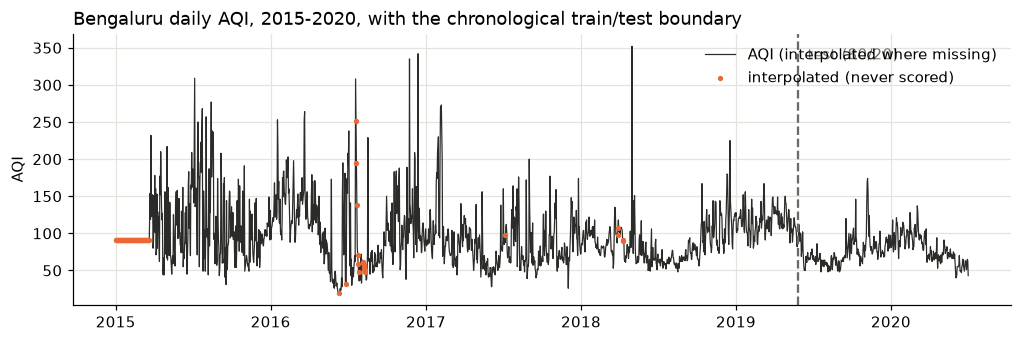

Train-period AQI mean 98.3 (std 41.9) vs test-period mean 77.5 (std 19.6)


In [3]:
# Validate one batch and the missing-value bookkeeping before any modelling.
loader = build_dataloader(cfg, "train", series)
x, y, target_day = next(iter(loader))
assert tuple(x.shape) == (1, 3, 11) and tuple(y.shape) == (1, 1)
assert not np.isnan(series.features).any() and not np.isnan(series.target).any()
test_days = series.window_end["test"] + series.horizon
print("One training batch: x", tuple(x.shape), "(batch, days, features) | y", tuple(y.shape))
print(f"AQI originally missing on {int((~series.target_observed).sum())} of {len(series.target_observed)} days; "
      f"observed test targets: {int(series.target_observed[test_days].sum())}/{len(test_days)}")

dates = pd.to_datetime(series.dates)
train_end = dates[series.window_end["train"][-1] + series.horizon]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(dates, series.target_aqi, color=COLORS["observed"], lw=0.8, label="AQI (interpolated where missing)")
ax.scatter(dates[~series.target_observed], series.target_aqi[~series.target_observed], s=6, color=COLORS["rbf"], label="interpolated (never scored)", zorder=3)
ax.axvline(train_end, color=COLORS["naive"], ls="--", lw=1.5)
ax.text(train_end, ax.get_ylim()[1] * 0.95, "  test (80/20)", color=COLORS["naive"], va="top")
ax.set_ylabel("AQI"); ax.set_title("Bengaluru daily AQI, 2015-2020, with the chronological train/test boundary", loc="left")
ax.legend(loc="upper right", frameon=False)
plt.show()
train_aqi = series.target_aqi[series.window_end["train"] + 1]
test_aqi = series.target_aqi[test_days]
print(f"Train-period AQI mean {train_aqi.mean():.1f} (std {train_aqi.std():.1f}) vs test-period mean {test_aqi.mean():.1f} (std {test_aqi.std():.1f})")

**Observation.**
- The training period (2015–mid-2019) has much larger AQI excursions than the test period (std ≈ 42 vs ≈ 20).
- The test-period mean is lower, ≈ 78 vs ≈ 98.
- All 402 test targets are observed AQI values.

**Inference.** There is a distribution shift between periods. A model that leans on the training-period level will over-predict on test. This matters later (Section 10).

**Remaining uncertainty.** The paper's exact data copy and split are not stated.

## 3. The method in equations

**Classical LSTM gates** (paper Eq. 4), with $v_t=[h_{t-1};x_t]$:
$$f_t=\sigma(W_f v_t+b_f),\quad i_t=\sigma(W_i v_t+b_i),\quad \tilde C_t=\tanh(W_C v_t+b_C),\quad o_t=\sigma(W_o v_t+b_o),$$
$$C_t=f_t\odot C_{t-1}+i_t\odot\tilde C_t,\qquad h_t=o_t\odot\tanh(C_t).$$

**QK-LSTM** (paper Eq. 6) replaces each linear map with a kernel expansion over $N$ reference vectors $v_j$:
$$g_t=\mathrm{act}\Big(\sum_{j=1}^{N}\alpha^{(g)}_j\,k(v_t,v_j)+b_g\Big),\qquad k(v,v')=\big|\langle 0|U^\dagger(v')\,U(v)|0\rangle\big|^2,$$
with the 4-qubit feature map $U(v)=U_{\mathrm{ent}}\,U_{\mathrm{enc}}(v)\,H^{\otimes 4}$ (Hadamards, then $R_y R_z$ angle encoding, then a CNOT chain).

**The paper is underspecified, so two readings are implemented.**
- The 27-dimensional $v_t$ (16 hidden + 11 inputs) must be mapped onto 4 qubits. Neither $N$, the angle map, nor the compression is stated.
- The paper's parameter count fixes the architecture: 209 = 112 + 80 + 17, the only decomposition that also reproduces the parent paper's 183.

| Variant | Gate computation | Trainable parameters |
|---|---|---|
| **Q-B** (count-matched) | $z_t=\mathrm{Linear}_{27\to4}(v_t)$; $a_t=\mathrm{Linear}_{4\to16}\big(k(z_t,z_j)_{j=1..4}\big)$ shared by all gates | $112+80+17=$ **209** |
| **Q-A** (Eq. 6 literally) | same compression; per-gate $\alpha^{(g)}\in\mathbb R^{N\times16}$, $N=4$ | $112+4(16N+16)+17=$ **449** |
| **Paper LSTM** | `torch.nn.LSTM(11,16)` + `Linear(16,1)` (two bias vectors per gate) | $4(11\cdot16+16\cdot16+32)+17=$ **1,873** |

References $v_j=[0;x_j]$ are fixed training-day inputs, and the circuit has no trainable parameters; both are required by the 209 count.

## 4. Known-answer sanity checks

Before trusting any result, the components must pass tests whose correct answer is known analytically. Each check below runs live in a few seconds.

1. The kernel is a true fidelity: $k(v,v)=1$, $k=k^\top$, $0\le k\le1$.
2. **The paper's text circuit factorises.** The CNOT chain is data-independent and appears on both sides of the overlap, so it cancels: $\langle\phi(v')|\phi(v)\rangle=\langle 0|H U_{\mathrm{enc}}(v')^\dagger \underbrace{U_{\mathrm{ent}}^\dagger U_{\mathrm{ent}}}_{=I} U_{\mathrm{enc}}(v) H|0\rangle$. The kernel is therefore a product of 4 single-qubit fidelities, and entanglement plays no role.
3. Autograd through the simulator equals the parameter-shift rule used by the paper.
4. The parameter counts in Section 3 come out exactly.

In [4]:
from lib.quantum_kernel import feature_map_states, fidelity_kernel, quantum_kernel

torch.manual_seed(0)
z = torch.randn(6, 4, dtype=torch.float64)
gram = fidelity_kernel(feature_map_states(z), feature_map_states(z))
print("1. diag(k) == 1:", torch.allclose(torch.diagonal(gram), torch.ones(6, dtype=torch.float64)),
      "| symmetric:", torch.allclose(gram, gram.T), "| range", round(float(gram.min()), 4), "-", round(float(gram.max()), 4))

z_ref = torch.randn(3, 4, dtype=torch.float64)
for layout in ("text", "figure"):
    full = quantum_kernel(z, z_ref, layout=layout)
    product = torch.ones_like(full)
    for q in range(4):
        product = product * quantum_kernel(z[:, q:q + 1], z_ref[:, q:q + 1], layout=layout)
    print(f"2. layout={layout!r}: max |k - product of single-qubit k| = {float((full - product).abs().max()):.2e}")

1. diag(k) == 1: True | symmetric: True | range 0.0016 - 1.0
2. layout='text': max |k - product of single-qubit k| = 1.44e-15
2. layout='figure': max |k - product of single-qubit k| = 2.77e-01


In [5]:
# 3. Autograd vs parameter-shift for d k / d z_0 (text layout; z_0 feeds one R_z and one R_y gate).
from lib.quantum_kernel import _apply_single_qubit, _cnot_chain_permutation, _ry, _rz

def shifted_kernel(zv, zr, qubit, gate, shift):
    state = torch.full((1, 16), 0.25, dtype=torch.complex128)
    for q in range(4):
        phi = zv[:, q] + (shift if (q == qubit and gate == "rz") else 0.0)
        theta = zv[:, q] + (shift if (q == qubit and gate == "ry") else 0.0)
        state = _apply_single_qubit(state, _rz(phi, torch.complex128), q, 4)
        state = _apply_single_qubit(state, _ry(theta, torch.complex128), q, 4)
    state = state[:, _cnot_chain_permutation(4)]
    return fidelity_kernel(state, feature_map_states(zr))[0, 0]

zv = torch.tensor([[0.4, -0.9, 1.3, 0.2]], dtype=torch.float64, requires_grad=True)
zr = torch.tensor([[1.1, 0.3, -0.5, 0.8]], dtype=torch.float64)
quantum_kernel(zv, zr)[0, 0].backward()
shift = sum((shifted_kernel(zv.detach(), zr, 0, g, math.pi / 2) - shifted_kernel(zv.detach(), zr, 0, g, -math.pi / 2)) / 2 for g in ("rz", "ry"))
print(f"3. dk/dz_0: autograd {float(zv.grad[0, 0]):+.12f} | parameter-shift {float(shift):+.12f}")

3. dk/dz_0: autograd +0.048548845318 | parameter-shift +0.048548845318


In [6]:
# 4. Parameter counts of every model used in the comparison.
from lib.models import build_torch_model, count_trainable_parameters, sample_reference_inputs

refs = sample_reference_inputs(series.features[series.window_end["train"]], 4, seed=0)
def kernel_cfg(kind, gate_mode, n=4):
    return {"type": kind, "params": {"gate_mode": gate_mode, "hidden_size": 16, "n_qubits": 4, "n_references": n, "rbf_gamma": 1.0}}
counts = {
    "Q-B QK-LSTM (count-matched)": count_trainable_parameters(build_torch_model(kernel_cfg("qk_lstm", "shared"), 11, refs)),
    "Q-A QK-LSTM (Eq. 6, N=4)": count_trainable_parameters(build_torch_model(kernel_cfg("qk_lstm", "per_gate"), 11, refs)),
    "Paper LSTM nn.LSTM(11,16)": count_trainable_parameters(build_torch_model({"type": "lstm", "params": {"hidden_size": 16}}, 11, None)),
    "Size-matched LSTM nn.LSTM(11,3)": count_trainable_parameters(build_torch_model({"type": "lstm", "params": {"hidden_size": 3}}, 11, None)),
    "RBF-kernel control (same as Q-B)": count_trainable_parameters(build_torch_model(kernel_cfg("rbf_lstm", "shared"), 11, refs)),
}
display(pd.Series(counts, name="trainable parameters").to_frame())
assert counts["Q-B QK-LSTM (count-matched)"] == 209 and counts["Paper LSTM nn.LSTM(11,16)"] == 1873

,trainable parameters
Q-B QK-LSTM (count-matched),209
"Q-A QK-LSTM (Eq. 6, N=4)",449
"Paper LSTM nn.LSTM(11,16)",1873
"Size-matched LSTM nn.LSTM(11,3)",196
RBF-kernel control (same as Q-B),209


**Observation.**
- The kernel is an exact fidelity.
- The text-circuit kernel equals the product of single-qubit kernels to machine precision ($\sim10^{-16}$), while the Fig. 2(d) layout does not.
- Autograd matches the parameter-shift rule.
- The paper's Table II counts (209 and 1,873) are reproduced exactly.

**Inference.**
- The building blocks are correct, so any later disagreement with the paper is not a kernel or gradient bug.
- The paper's circuit, as written, contains no entanglement effect.

**Claim impact.** C2's parameter *count* is reproduced, but whether the count buys accuracy is still open (Section 8). C4's premise, a rich entangled feature space, is weakened for the text circuit.

## 5. Model walkthrough: one forward pass of Q-B

Q-B processes a 3-day window step by step:
1. Compress $v_t$ to 4 numbers.
2. Compute the 4 kernel similarities to the reference vectors.
3. Map them to a 16-dimensional gate pre-activation shared by all gates.
4. Update the cell state.

The final hidden state is read out by `Linear(16,1)` as the scaled next-day AQI.

In [7]:
torch.manual_seed(0)
model = build_torch_model(kernel_cfg("qk_lstm", "shared"), 11, refs)
x_window, y_window, day = next(iter(build_dataloader(cfg, "test", series)))
x_one = x_window[:1]
h = torch.zeros(1, 16); c = torch.zeros(1, 16)
with torch.no_grad():
    for step in range(3):
        v = torch.cat([h, x_one[:, step]], dim=1)
        z_t = model.cell.compression(v)
        k_t = model.cell.kernel_features(v)
        h, c = model.cell(x_one[:, step], (h, c))
        print(f"day t-{2 - step}: v {tuple(v.shape)} -> z {np.round(z_t.numpy()[0], 3)} -> kernel to 4 refs {np.round(k_t.numpy()[0], 3)}")
    prediction = series.to_aqi(model.head(h).numpy()[0, 0])
print(f"Untrained prediction for {pd.Timestamp(series.dates[int(day[0])]).date()}: AQI {prediction:.1f} (observed {series.target_aqi[int(day[0])]:.1f})")

day t-2: v (1, 27) -> z [ 0.092  0.111 -0.006  0.09 ] -> kernel to 4 refs [0.987 0.996 0.988 0.993]
day t-1: v (1, 27) -> z [0.119 0.031 0.155 0.058] -> kernel to 4 refs [0.995 0.979 0.986 0.994]
day t-0: v (1, 27) -> z [0.097 0.027 0.24  0.071] -> kernel to 4 refs [0.985 0.959 0.969 0.988]
Untrained prediction for 2019-05-27: AQI 54.3 (observed 92.0)


Before training, the compression maps the inputs and the references to nearby points, so every kernel value is close to 1 and carries little information. Training has to learn a compression that spreads them out. This is the only place the input enters the gates: the kernel sees the data through a learned 4-dimensional bottleneck.

## 6. Small live experiment (smoke budget)

This trains four models live through the same `lib/runner.py` entry point used for every stored run, writing full evidence files (`run.log`, `run_status.json`, `metrics.json`):
- QK-LSTM Q-B (quantum kernel);
- its RBF-kernel control;
- the size-matched LSTM;
- persistence.

**Budget:** 3 epochs instead of 20, one seed. This is a *smoke-scale* demonstration that the pipeline trains end to end on the real data. It is **not** evidence for or against the claims: those rest on the stored 20-epoch, 5-seed runs in Sections 7–11. Expected runtime on a laptop CPU is 1–3 minutes.

In [8]:
import copy
import logging
from lib.experiment_logging import configure_logging
from lib.runner import train_and_evaluate

LIVE_EPOCHS, LIVE_SEED = 3, 0
# (display name, evidence folder) -> model config; each run gets its own folder.
live_models = {
    ("Q-B QK-LSTM (quantum)", "qb_quantum"): {"type": "qk_lstm", "params": {"gate_mode": "shared", "hidden_size": 16, "n_qubits": 4, "n_references": 4, "circuit_layout": "text", "angle_map": "identity"}},
    ("Q-B RBF-kernel control", "qb_rbf"): {"type": "rbf_lstm", "params": {"gate_mode": "shared", "hidden_size": 16, "n_qubits": 4, "n_references": 4, "rbf_gamma": 1.0}},
    ("LSTM(3), 196 params", "lstm3"): {"type": "lstm", "params": {"hidden_size": 3}},
    ("Persistence", "persistence"): {"type": "persistence", "params": {}},
}
live_root = PROJECT_DIR / "outdir" / "notebook_live" / time.strftime("%Y%m%d-%H%M%S")
live_rows = []
for (name, folder), model_cfg in live_models.items():
    run_cfg = copy.deepcopy(cfg)
    run_cfg.update(model=model_cfg, seed=LIVE_SEED, num_threads=1)
    run_cfg["training"]["epochs"] = LIVE_EPOCHS
    run_dir = live_root / folder
    assert not run_dir.exists(), f"refusing to reuse {run_dir}"
    configure_logging(run_dir / "run.log", level=logging.INFO, console=False)
    torch.manual_seed(LIVE_SEED); np.random.seed(LIVE_SEED)
    started = time.perf_counter()
    metrics = train_and_evaluate(run_cfg, run_dir)
    test = metrics["splits"]["test"]["observed_targets"]
    live_rows.append({"model": name, "params": metrics["trainable_parameters"], "test RMSE": test["rmse"], "test R²": test["r2"],
                      "status": json.loads((run_dir / "run_status.json").read_text())["status"], "seconds": time.perf_counter() - started})
logging.getLogger().handlers.clear()
display(pd.DataFrame(live_rows).set_index("model").round(3))
print("Evidence written under", live_root.relative_to(PROJECT_DIR))

,params,test RMSE,test R²,status,seconds
model,,,,,
Q-B QK-LSTM (quantum),209,17.155,0.234,COMPLETED,38.888
Q-B RBF-kernel control,209,17.059,0.242,COMPLETED,3.094
"LSTM(3), 196 params",196,20.359,-0.079,COMPLETED,2.418
Persistence,0,11.415,0.661,COMPLETED,0.173


Evidence written under outdir/notebook_live/20261029-164230


**Observation.** All four runs complete through the real runner and write structured evidence. After 3 epochs the models are under-trained and these single-seed numbers move by several RMSE between seeds. They show that the software executes and the models learn, nothing more.

**Claim impact:** none. This is a smoke check only.

## 7. Headline reproduction result

The stored evidence is sweep **S1**: every model at the paper's Table II hyperparameters (20 epochs, batch 1, Adam lr 1e-3, sequence length 3), 80/20 split, **5 seeds (0–4)**. The helper below reads each run's `run_status.json` and `metrics.json` directly. It refuses incomplete, duplicate or non-finite runs, so the tables are recomputed here from structured artifacts.

In [9]:
def sweep_dir(prefix):
    matches = sorted(SWEEPS.glob(f"{prefix}_2*"))
    assert len(matches) == 1, f"expected exactly one sweep for {prefix}, found {matches}"
    return matches[0]

def load_runs(prefix, candidate, split="test", seeds=(0, 1, 2, 3, 4)):
    # Return {seed: metrics} for one candidate, validating completeness and status.
    directory = sweep_dir(prefix)
    status = json.loads((directory / "sweep_status.json").read_text())
    runs = [r for r in status["runs"] if r["candidate"] == candidate and r["status"] == "COMPLETED"]
    by_seed = {}
    for run in runs:
        run_status = json.loads((directory / run["run_status"]).read_text())
        assert run_status["status"] == "COMPLETED", run
        assert run["seed"] not in by_seed, f"duplicate seed {run['seed']} for {candidate}"
        metrics = json.loads((directory / run["metrics_path"]).read_text())
        values = metrics["splits"][split]["observed_targets"]
        assert all(math.isfinite(values[m]) for m in ("rmse", "mae", "mape", "r2"))
        by_seed[run["seed"]] = {**values, "params": metrics["trainable_parameters"], "run_dir": directory / run["run_dir"]}
    assert set(by_seed) == set(seeds), f"{prefix}:{candidate} has seeds {sorted(by_seed)}, expected {list(seeds)}"
    return by_seed

def summary(by_seed, metric="rmse"):
    values = [by_seed[s][metric] for s in sorted(by_seed)]
    return statistics.fmean(values), (statistics.stdev(values) if len(values) > 1 else 0.0), values

def paired(a, b, metric="rmse"):
    # Same-seed difference A - B with a two-sided 95% t-interval (n = number of seeds).
    diffs = np.array([a[s][metric] - b[s][metric] for s in sorted(a)])
    half = stats.t.ppf(0.975, len(diffs) - 1) * diffs.std(ddof=1) / math.sqrt(len(diffs)) if diffs.std(ddof=1) > 0 else 0.0
    low, high = diffs.mean() - half, diffs.mean() + half
    verdict = "A better" if high < 0 else ("A worse" if low > 0 else "not separated")
    return {"mean": float(diffs.mean()), "ci_low": float(low), "ci_high": float(high), "A better on seeds": f"{int((diffs < 0).sum())}/{len(diffs)}", "decision": verdict}

S1 = "s1_paper_hp"
qb, qa, lstm16 = load_runs(S1, "QB_quantum_209"), load_runs(S1, "QA_quantum_eq6_N4"), load_runs(S1, "B1_lstm_1873")
print("S1 sweep:", sweep_dir(S1).name, "| status:", json.loads((sweep_dir(S1) / "sweep_status.json").read_text())["status"])

S1 sweep: s1_paper_hp_20261021-134301 | status: COMPLETED


In [10]:
PAPER = {"QK-LSTM": {"rmse": 9.20, "mae": 7.15, "mape": 9.14, "r2": 0.84}, "LSTM": {"rmse": 15.94, "mae": 11.07, "mape": 13.32, "r2": 0.78}}
rows = []
for paper_name, label, runs in (("QK-LSTM", "Q-B QK-LSTM (209 params)", qb), ("QK-LSTM", "Q-A QK-LSTM (449 params)", qa), ("LSTM", "Paper LSTM (1,873 params)", lstm16)):
    for metric in ("rmse", "mae", "mape", "r2"):
        mean, std, values = summary(runs, metric)
        rows.append({"model": label, "metric": metric.upper(), "paper (1 run)": PAPER[paper_name][metric],
                     "reproduced mean": mean, "sample std (5 seeds)": std, "per-seed values": np.round(values, 2).tolist()})
headline = pd.DataFrame(rows).set_index(["model", "metric"])
display(headline.round(3))
display(pd.DataFrame([paired(qb, lstm16)], index=["Q-B QK-LSTM − paper LSTM (test RMSE)"]).round(3))

paper (1 run)  reproduced mean  \
model                     metric                                   
Q-B QK-LSTM (209 params)  RMSE             9.20           15.679   
                          MAE              7.15           12.381   
                          MAPE             9.14           16.534   
                          R2               0.84            0.327   
Q-A QK-LSTM (449 params)  RMSE             9.20           15.661   
                          MAE              7.15           12.203   
                          MAPE             9.14           16.243   
                          R2               0.84            0.332   
Paper LSTM (1,873 params) RMSE            15.94           12.611   
                          MAE             11.07           10.056   
                          MAPE            13.32           13.454   
                          R2               0.78            0.571   

                                  sample std (5 seeds)  \
model                     metric                         
Q-B QK-LSTM (209 params)  RMSE                   3.965   
                          MAE                    4.011   
                          MAPE                   5.960   
                          R2                     0.328   
Q-A QK-LSTM (449 params)  RMSE                   3.771   
                          MAE                    3.802   
                          MAPE                   5.670   
                          R2                     0.315   
Paper LSTM (1,873 params) RMSE                   2.661   
                          MAE                    2.667   
                          MAPE                   4.048   
                          R2                     0.185   

                                                      per-seed values  
model                     metric                                       
Q-B QK-LSTM (209 params)  RMSE     [15.3, 19.19, 20.24, 11.78, 11.88]  
                          MAE       [12.17, 15.78, 17.05, 8.41, 8.49]  
                          MAPE    [16.61, 21.44, 23.43, 10.56, 10.64]  
                          R2          [0.39, 0.04, -0.07, 0.64, 0.63]  
Q-A QK-LSTM (449 params)  RMSE    [14.83, 18.98, 20.19, 12.33, 11.97]  
                          MAE        [11.39, 15.49, 16.81, 8.8, 8.52]  
                          MAPE       [15.42, 21.0, 23.1, 11.0, 10.69]  
                          R2           [0.43, 0.06, -0.06, 0.6, 0.63]  
Paper LSTM (1,873 params) RMSE      [11.02, 14.2, 16.49, 11.3, 10.05]  
                          MAE          [8.9, 11.37, 14.07, 8.5, 7.44]  
                          MAPE     [12.14, 15.24, 19.57, 11.01, 9.31]  
                          R2           [0.68, 0.48, 0.29, 0.67, 0.74]

,mean,ci_low,ci_high,A better on seeds,decision
Q-B QK-LSTM − paper LSTM (test RMSE),3.068,0.757,5.379,0/5,A worse


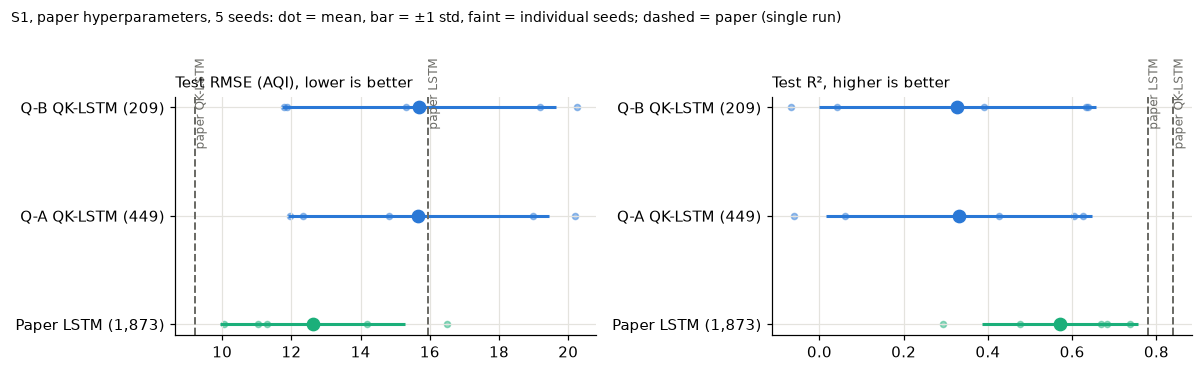

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for axis, metric, title in ((axes[0], "rmse", "Test RMSE (AQI), lower is better"), (axes[1], "r2", "Test R², higher is better")):
    for y, (label, runs, color) in enumerate((("Paper LSTM (1,873)", lstm16, COLORS["lstm"]), ("Q-A QK-LSTM (449)", qa, COLORS["quantum"]), ("Q-B QK-LSTM (209)", qb, COLORS["quantum"]))):
        mean, std, values = summary(runs, metric)
        axis.errorbar(mean, y, xerr=std, fmt="o", ms=8, color=color, elinewidth=2)
        axis.scatter(values, [y] * len(values), s=16, color=color, alpha=0.45)
    for name, value in PAPER.items():
        axis.axvline(value[metric], ls="--", color=COLORS["naive"], lw=1.3)
        axis.text(value[metric], 2.45, f" paper {name}", rotation=90, va="top", fontsize=8, color=COLORS["naive"])
    axis.set_yticks(range(3)); axis.set_yticklabels(["Paper LSTM (1,873)", "Q-A QK-LSTM (449)", "Q-B QK-LSTM (209)"])
    axis.set_title(title, loc="left", fontsize=10)
fig.suptitle("S1, paper hyperparameters, 5 seeds: dot = mean, bar = ±1 std, faint = individual seeds; dashed = paper (single run)", fontsize=9, x=0.01, ha="left")
plt.tight_layout(); plt.show()

**A consistency check on the paper's own Table I.** On a single test set, $\mathrm{Var}(y)=\mathrm{RMSE}^2/(1-R^2)$ is a property of the targets alone, so every row of a results table must imply the same value. The next cell computes it for the paper's rows and for ours.

In [12]:
check = []
for name, value in PAPER.items():
    check.append({"source": f"paper {name}", "RMSE": value["rmse"], "R²": value["r2"], "implied test std (AQI)": math.sqrt(value["rmse"] ** 2 / (1 - value["r2"]))})
for label, runs in (("ours: Q-B QK-LSTM, seed 0", qb), ("ours: paper LSTM, seed 0", lstm16)):
    check.append({"source": label, "RMSE": runs[0]["rmse"], "R²": runs[0]["r2"], "implied test std (AQI)": math.sqrt(runs[0]["rmse"] ** 2 / (1 - runs[0]["r2"]))})
display(pd.DataFrame(check).set_index("source").round(2))
print(f"Actual std of our 402 observed test targets: {series.target_aqi[test_days][series.target_observed[test_days]].std():.2f} AQI")

,RMSE,R²,implied test std (AQI)
source,,,
paper QK-LSTM,9.20,0.84,23.00
paper LSTM,15.94,0.78,33.98
"ours: Q-B QK-LSTM, seed 0",15.30,0.39,19.59
"ours: paper LSTM, seed 0",11.02,0.68,19.59


Actual std of our 402 observed test targets: 19.59 AQI


**Observation.**
- Reproduced QK-LSTM test RMSE is 15.7 ± 4.0, against the paper's 9.20; R² is 0.33, against 0.84.
- The reproduced paper LSTM is *better* than the paper reports (12.6 vs 15.94 RMSE), and it beats QK-LSTM on every seed.
- Our two models imply the same test std (19.6, as they must). The paper's two rows imply **23.0 and 34.0**.

**Inference.**
- The paper's metric values are not reproduced, and its ranking is reversed.
- The paper's Table I cannot come from two single, pooled evaluations on the same targets using its own definitions (Eq. 20, 23), even allowing for rounding: ±0.005 on every value gives non-overlapping variance ranges (512–547 vs 1,129–1,183).
- The cause is unknown. One candidate is an "R²" computed as squared correlation, which ignores systematic bias (`results/r2_variant_check.md`: our paper-style LSTM has squared correlation 0.75 vs standard R² 0.57). A common rescaling of the data cannot explain it.

**Remaining uncertainty.** Unknown forecast horizon, split and data copy (tested in Sections 9–10); the paper used single runs.

**Claim impact.** C1 is contradicted on this protocol: QK-LSTM is worse than the paper's own baseline, 0/5 seeds better, with a 95% CI entirely above 0.

## 8. Fair baseline comparison

The paper's only baseline is one untuned run of a 1,873-parameter LSTM. That cannot test a *compactness* claim (C2), and an untuned baseline cannot test an *accuracy* claim (C1). The baselines below were declared before any result was seen (`LOG.md`, *Fair Baseline Plan*, Phase 1).

**Fairness, dimension by dimension.** "Same" and "matched" are used only where literally true.

| Baseline | Information and inputs | Parameters | Training data | Optimisation steps | Tuning budget | Compute / wall time | Evaluation protocol |
|---|---|---|---|---|---|---|---|
| Paper LSTM `nn.LSTM(11,16)` | same 3×11 window | 1,873 (9× more than Q-B) | same 1,604 windows | same: 20 epochs × batch 1 | same lr grid on validation | far cheaper (no simulation) | same split, metric, final epoch, seeds |
| Size-matched LSTM `nn.LSTM(11,3)` | same 3×11 window | **approximately matched: 196 vs 209 (−6%, within the predeclared ±10%)** | same | same | same lr grid | far cheaper | same |
| RBF-kernel QK-LSTM (control) | same | **identical (209 / 449)** | same | same | same lr grid; RBF γ fixed at 1, untuned | cheaper | same; seed-paired initialisation and references |
| Persistence ŷ(t+1) = AQI(t) | **different**: uses past AQI, which the learned models do not see | 0 | none | none | none | negligible | same test days and metric |
| Ridge on 3×11 window | same | 34 | same | closed form | α grid on validation | negligible | same |

**Tuning (applies to every trained model).**
- The learning rate was chosen from {1e-3, 3e-3, 1e-2} by mean *validation* RMSE over 3 seeds (sweep S3). The kernel models were also searched over N ∈ {4, 16}.
- Selection rule: ties within 1% go to fewer parameters, then the smaller lr.
- Selected: lr 1e-3 for every kernel model (the paper's value) and lr 1e-2 for both LSTMs (sweep S4 reruns them on the full training block).
- The test set was not used.

In [13]:
S4 = "s4_tuned_test"
tuned = {
    "Persistence (0)": load_runs(S1, "B0_persistence"),
    "Ridge (34)": load_runs(S1, "B0b_ridge"),
    "LSTM(3) size-matched (196)": load_runs(S4, "B2_lstm3_lr0.01"),
    "Paper LSTM(16) (1,873)": load_runs(S4, "B1_lstm16_lr0.01"),
    "Q-B QK-LSTM quantum (209)": qb,
    "Q-A QK-LSTM quantum (449)": qa,
    "Q-B RBF control (209)": load_runs(S1, "B3B_rbf_209"),
    "Q-A RBF control (449)": load_runs(S1, "B3A_rbf_eq6_N4"),
}
family = lambda name: "naive" if name.startswith(("Persistence", "Ridge")) else ("lstm" if "LSTM(" in name else ("rbf" if "RBF" in name else "quantum"))

def wall_minutes(by_seed):
    out = []
    for run in by_seed.values():
        s = json.loads((run["run_dir"] / "run_status.json").read_text())
        out.append((pd.Timestamp(s["completed_at"]) - pd.Timestamp(s["started_at"])).total_seconds() / 60)
    return statistics.fmean(out)

table = []
for name, runs in tuned.items():
    rmse_mean, rmse_std, rmse_values = summary(runs, "rmse")
    table.append({"model (params)": name, "RMSE mean": rmse_mean, "RMSE std": rmse_std, "R² mean": summary(runs, "r2")[0],
                  "per-seed RMSE": np.round(rmse_values, 2).tolist(), "wall-clock / run (min)": wall_minutes(runs)})
display(pd.DataFrame(table).set_index("model (params)").round(3))

,RMSE mean,RMSE std,R² mean,per-seed RMSE,wall-clock / run (min)
model (params),,,,,
Persistence (0),11.415,0.000,0.661,"[11.42, 11.42, 11.42, 11.42, 11.42]",0.000
Ridge (34),12.425,0.000,0.598,"[12.42, 12.42, 12.42, 12.42, 12.42]",0.010
LSTM(3) size-matched (196),11.717,2.139,0.633,"[12.26, 12.43, 14.66, 9.56, 9.68]",0.173
"Paper LSTM(16) (1,873)",12.882,2.778,0.552,"[12.84, 13.33, 17.26, 10.49, 10.49]",0.193
Q-B QK-LSTM quantum (209),15.679,3.965,0.327,"[15.3, 19.19, 20.24, 11.78, 11.88]",10.640
Q-A QK-LSTM quantum (449),15.661,3.771,0.332,"[14.83, 18.98, 20.19, 12.33, 11.97]",9.420
Q-B RBF control (209),16.006,3.801,0.303,"[15.56, 19.33, 20.45, 12.47, 12.22]",0.677
Q-A RBF control (449),15.927,3.855,0.308,"[15.2, 19.36, 20.47, 12.63, 11.98]",0.737


,mean,ci_low,ci_high,A better on seeds,decision
C1: Q-B QK-LSTM − paper LSTM,2.797,0.496,5.098,0/5,A worse
C1: Q-A QK-LSTM − paper LSTM,2.779,0.681,4.877,0/5,A worse
C2: Q-B QK-LSTM − size-matched LSTM,3.963,1.372,6.554,0/5,A worse
floor: Q-B QK-LSTM − persistence,4.264,-0.659,9.188,0/5,not separated


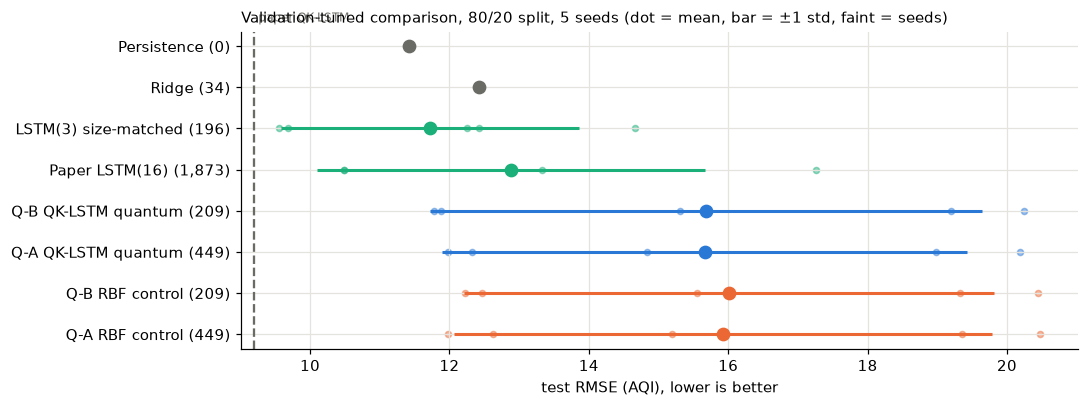

In [14]:
decisions = pd.DataFrame(
    [paired(tuned["Q-B QK-LSTM quantum (209)"], tuned["Paper LSTM(16) (1,873)"]),
     paired(tuned["Q-A QK-LSTM quantum (449)"], tuned["Paper LSTM(16) (1,873)"]),
     paired(tuned["Q-B QK-LSTM quantum (209)"], tuned["LSTM(3) size-matched (196)"]),
     paired(tuned["Q-B QK-LSTM quantum (209)"], tuned["Persistence (0)"])],
    index=["C1: Q-B QK-LSTM − paper LSTM", "C1: Q-A QK-LSTM − paper LSTM", "C2: Q-B QK-LSTM − size-matched LSTM", "floor: Q-B QK-LSTM − persistence"])
display(decisions.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
for y, (name, runs) in enumerate(tuned.items()):
    mean, std, values = summary(runs)
    color = COLORS[family(name)]
    ax.errorbar(mean, y, xerr=std, fmt="o", ms=8, color=color, elinewidth=2)
    ax.scatter(values, [y] * len(values), s=16, color=color, alpha=0.45)
ax.axvline(PAPER["QK-LSTM"]["rmse"], ls="--", color=COLORS["naive"]); ax.text(PAPER["QK-LSTM"]["rmse"], -0.6, " paper QK-LSTM", fontsize=8, color=COLORS["naive"])
ax.set_yticks(range(len(tuned))); ax.set_yticklabels(list(tuned)); ax.invert_yaxis()
ax.set_xlabel("test RMSE (AQI), lower is better")
ax.set_title("Validation-tuned comparison, 80/20 split, 5 seeds (dot = mean, bar = ±1 std, faint = seeds)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Observation.**
- After equal tuning, both LSTMs, ridge and persistence all have lower test RMSE than either QK-LSTM variant.
- The QK-LSTM is worse than the paper's LSTM on 5/5 seeds, with a 95% CI above 0.
- It is also worse than an LSTM with 13 *fewer* parameters, again 5/5 seeds and a CI above 0.

**Inference.** The parameter saving does not come with comparable accuracy: a classical model of the same size is clearly better. The paper's lr 1e-3 under-trained the LSTM, so the paper's fixed protocol, if anything, favoured QK-LSTM.

**Scope note.** This comparison uses the paper's preprocessing (two-sided interpolation). §10d shows the LSTM's advantage over QK-LSTM shrinks to *not separated* when gaps are filled causally.

**Remaining uncertainty.**
- Persistence and the paper LSTM are not separated from each other (wide seed spread).
- Wall-clock is descriptive only: some runs shared the CPU with other jobs, and simulation overhead is an implementation cost.

**Claim impact.**
- C1: contradicted against the paper's baseline.
- C2: the parameter count holds, but the compactness *advantage* is contradicted by the size-matched LSTM.

## 9. Controls and ablations

The paper's explanation is that *the quantum feature space* captures nonlinear structure (C4). Three credible alternatives could explain any result as well:
- (a) any smooth kernel on the learned 4-dimensional compression would do;
- (b) the circuit details (layout, angle map, number of references) matter;
- (c) the paper's numbers come from an easier protocol, for example a same-day horizon.

### 9a. Quantum kernel vs classical RBF kernel at an identical architecture

Same seeds give the same initial weights and the same reference vectors, so the paired difference isolates the kernel.

In [15]:
kernel_control = pd.DataFrame(
    [paired(qb, tuned["Q-B RBF control (209)"]), paired(qa, tuned["Q-A RBF control (449)"])],
    index=["Q-B: quantum − RBF", "Q-A: quantum − RBF"])
display(kernel_control.round(3))
print(f"For scale: seed-to-seed RMSE std of Q-B is {summary(qb)[1]:.2f} AQI; the QK-LSTM − paper-LSTM gap is {paired(qb, lstm16)['mean']:.2f} AQI.")

,mean,ci_low,ci_high,A better on seeds,decision
Q-B: quantum − RBF,-0.326,-0.591,-0.062,5/5,A better
Q-A: quantum − RBF,-0.266,-0.452,-0.080,5/5,A better


For scale: seed-to-seed RMSE std of Q-B is 3.97 AQI; the QK-LSTM − paper-LSTM gap is 3.07 AQI.


### 9b. Circuit layout, angle map and number of references (validation split only)

These were checked in the tuning sweep S3, on the **validation** block (2018-12-18..2019-05-26, 3 seeds), so this selection never touched the test set.
- **Layout:** the Fig. 2(d) "figure" layout re-applies the encoding after the CNOT chain, so entanglement no longer cancels.
- **Angle map:** the paper does not specify it; three choices are compared.
- **N:** 4 vs 16 reference vectors.

In [16]:
S3 = "s3_val_tuning"
val = lambda cand: load_runs(S3, cand, split="validation", seeds=(0, 1, 2))
variants = {
    "Q-B text circuit, identity angles (default)": "QB_quantum_lr0.001",
    "Q-B Fig. 2(d) entangling layout": "D2_QB_figure_lr0.001",
    "Q-B arctan angle map": "ANG_QB_arctan_lr0.001",
    "Q-B π·tanh angle map": "ANG_QB_tanhpi_lr0.001",
    "Q-A N=4 references": "QA_quantum_N4_lr0.001",
    "Q-A N=16 references": "QA_quantum_N16_lr0.001",
    "Q-A Fig. 2(d) layout, N=4": "D2_QA_figure_N4_lr0.001",
    "Q-B RBF control": "B3B_rbf_lr0.001",
    "Persistence (validation window)": "B0_persistence_val",
}
rows = []
for label, cand in variants.items():
    runs = val(cand)
    mean, std, values = summary(runs)
    rows.append({"variant": label, "validation RMSE mean": mean, "std (3 seeds)": std, "per-seed": np.round(values, 2).tolist()})
display(pd.DataFrame(rows).set_index("variant").round(3))
display(pd.DataFrame([paired(val("D2_QB_figure_lr0.001"), val("QB_quantum_lr0.001")), paired(val("QB_quantum_lr0.001"), val("B3B_rbf_lr0.001"))],
                     index=["Q-B Fig. 2(d) layout − text layout (validation)", "Q-B quantum − RBF (validation)"]).round(3))

,validation RMSE mean,std (3 seeds),per-seed
variant,,,
"Q-B text circuit, identity angles (default)",15.897,0.507,"[15.95, 16.38, 15.37]"
Q-B Fig. 2(d) entangling layout,16.120,0.694,"[16.33, 16.68, 15.35]"
Q-B arctan angle map,15.901,0.339,"[15.65, 16.29, 15.77]"
Q-B π·tanh angle map,16.159,1.834,"[15.55, 18.22, 14.7]"
Q-A N=4 references,16.385,1.084,"[16.02, 17.61, 15.53]"
Q-A N=16 references,17.138,0.191,"[17.36, 17.02, 17.04]"
"Q-A Fig. 2(d) layout, N=4",16.463,1.448,"[15.69, 18.13, 15.57]"
Q-B RBF control,15.819,0.620,"[15.69, 16.49, 15.27]"
Persistence (validation window),17.133,0.000,"[17.13, 17.13, 17.13]"


,mean,ci_low,ci_high,A better on seeds,decision
Q-B Fig. 2(d) layout − text layout (validation),0.223,-0.309,0.756,1/3,not separated
Q-B quantum − RBF (validation),0.078,-0.386,0.542,1/3,not separated


### 9c. Protocol: same-day horizon and a known-answer test

- **Same-day horizon.** The paper does not state its forecast horizon. Sweep S5 re-ran the models predicting *same-day* AQI (horizon 0) from windows ending that day, an easier nowcasting task.
- **Known answer.** Sweep S5c used the PM2.5 of the last input day as the target, with preprocessing disabled so the target is exactly an input. Every correct pipeline should reach R² ≈ 1.
- S5's first known-answer attempt hit a loader bug, since fixed and covered by a regression test. Its known-answer runs were re-run in S5b and S5c, so S5 itself stays a partial sweep (12/18).
- Both are diagnostics on 3 seeds, not part of any claim comparison.

In [17]:
S5, S5C = "s5_gap_diagnostics", "s5c_known_answer_clean"
rows = []
for label, prefix, cand in (("same-day AQI: ridge", S5, "H0_aqi_B0b_ridge"), ("same-day AQI: paper LSTM(16)", S5, "H0_aqi_B1_lstm16"),
                            ("same-day AQI: LSTM(3)", S5, "H0_aqi_B2_lstm3"), ("same-day AQI: Q-B QK-LSTM", S5, "H0_aqi_QB_quantum"),
                            ("known answer (target = input PM2.5): Q-B QK-LSTM", S5C, "KAc_pm25_QB_quantum_lr0.001"),
                            ("known answer (target = input PM2.5): LSTM(16), lr 1e-2", S5C, "KAc_pm25_B1_lstm16_lr0.01")):
    runs = load_runs(prefix, cand, seeds=(0, 1, 2))
    rows.append({"diagnostic": label, "test RMSE mean": summary(runs)[0], "test R² mean": summary(runs, "r2")[0],
                 "per-seed R²": np.round(summary(runs, "r2")[2], 3).tolist()})
display(pd.DataFrame(rows).set_index("diagnostic").round(3))
print("S5 sweep status:", json.loads((sweep_dir(S5) / "sweep_status.json").read_text())["status"], "(known-answer candidates superseded by S5b/S5c)")

,test RMSE mean,test R² mean,per-seed R²
diagnostic,,,
same-day AQI: ridge,9.433,0.768,"[0.768, 0.768, 0.768]"
same-day AQI: paper LSTM(16),10.337,0.707,"[0.517, 0.787, 0.819]"
same-day AQI: LSTM(3),13.056,0.530,"[0.203, 0.687, 0.701]"
same-day AQI: Q-B QK-LSTM,15.335,0.347,"[-0.137, 0.546, 0.631]"
known answer (target = input PM2.5): Q-B QK-LSTM,0.809,0.996,"[0.995, 0.998, 0.995]"
"known answer (target = input PM2.5): LSTM(16), lr 1e-2",2.510,0.950,"[0.877, 0.981, 0.993]"


S5 sweep status: PARTIAL (known-answer candidates superseded by S5b/S5c)


**Observation.**
- (9a) The quantum kernel is better than the RBF kernel by about 0.3 RMSE on this window, consistently across seeds. That is about 10× smaller than the gap to the LSTM, and Section 10 shows it does not survive a change of test window.
- (9b) No circuit choice helps on validation: neither the entangling Fig. 2(d) layout, nor any angle map, nor more references. On the validation window the RBF control is even slightly *better* than the quantum kernel (15.82 vs 15.90).
- (9c) Two results:
  - Same-day prediction brings ridge and the LSTM close to the paper's QK-LSTM RMSE of 9.2, but not QK-LSTM.
  - The known-answer test is passed by QK-LSTM (R² ≈ 0.996). The LSTM reaches R² ≈ 0.95 with one under-converged seed.

**Inference.**
- The QK-LSTM's behaviour is explained by alternative (a): a learned 4-dimensional bottleneck followed by *some* smooth similarity. The quantum circuit specifically adds little.
- The pipeline is correct (known answer), so the gap to the paper is not a bug. An easier protocol (c) would explain part of the paper's metric level, but not its ranking.

**Remaining uncertainty.** The RBF bandwidth γ was not tuned, which limits how strongly the small quantum-vs-RBF difference can be interpreted.

**Claim impact.** C4 is contradicted: there is no gain over classical models to attribute to the quantum kernel, and kernel swaps barely move the result.

## 10. Robustness and uncertainty

### 10a. A different test window: calendar 2020 (the paper's text)

Sweep S2 repeats S1 with the test set = 2020-01-01..2020-07-01 (183 days), as the paper's text states.

In [18]:
S2 = "s2_split2020"
s2 = {name: load_runs(S2, cand) for name, cand in (("Q-B QK-LSTM", "QB_quantum_209"), ("paper LSTM", "B1_lstm_1873"), ("LSTM(3)", "B2_lstm_matched_196"),
                                                   ("Q-B RBF", "B3B_rbf_209"), ("persistence", "B0_persistence"), ("ridge", "B0b_ridge"))}
display(pd.DataFrame({name: {"RMSE mean": summary(r)[0], "RMSE std": summary(r)[1], "R² mean": summary(r, "r2")[0]} for name, r in s2.items()}).T.round(3))
display(pd.DataFrame([paired(s2["Q-B QK-LSTM"], s2["paper LSTM"]), paired(s2["Q-B QK-LSTM"], s2["LSTM(3)"]), paired(s2["Q-B QK-LSTM"], s2["Q-B RBF"])],
                     index=["Q-B − paper LSTM", "Q-B − LSTM(3)", "Q-B quantum − RBF"]).round(3))

,RMSE mean,RMSE std,R² mean
Q-B QK-LSTM,12.318,2.614,0.583
paper LSTM,11.325,1.656,0.654
LSTM(3),11.619,1.777,0.635
Q-B RBF,12.327,2.467,0.584
persistence,10.455,0.000,0.710
ridge,9.943,0.000,0.738


,mean,ci_low,ci_high,A better on seeds,decision
Q-B − paper LSTM,0.993,-1.251,3.238,2/5,not separated
Q-B − LSTM(3),0.699,-0.417,1.816,2/5,not separated
Q-B quantum − RBF,-0.009,-0.375,0.357,2/5,not separated


### 10b. Where the errors come from: bias under distribution shift

The test period has lower AQI than the training period (Section 2). The mean signed error (prediction − observation) on test days, averaged over seeds, shows which models carry that shift into their forecasts.

In [19]:
def signed_error(by_seed, split="test"):
    errors = []
    for run in by_seed.values():
        frame = pd.read_csv(run["run_dir"] / "predictions.csv")
        frame = frame[(frame.split == split) & frame.target_observed]
        errors.append(float((frame.aqi_pred - frame.aqi_true).mean()))
    return statistics.fmean(errors)

bias = {name: {"test bias (AQI)": signed_error(runs), "train bias (AQI)": signed_error(runs, "train")} for name, runs in tuned.items()}
display(pd.DataFrame(bias).T.round(2))

,test bias (AQI),train bias (AQI)
Persistence (0),0.12,-0.13
Ridge (34),6.92,-0.37
LSTM(3) size-matched (196),5.12,-0.64
"Paper LSTM(16) (1,873)",4.96,-1.05
Q-B QK-LSTM quantum (209),7.99,-0.51
Q-A QK-LSTM quantum (449),7.54,-0.82
Q-B RBF control (209),8.04,-0.37
Q-A RBF control (449),7.61,-0.58


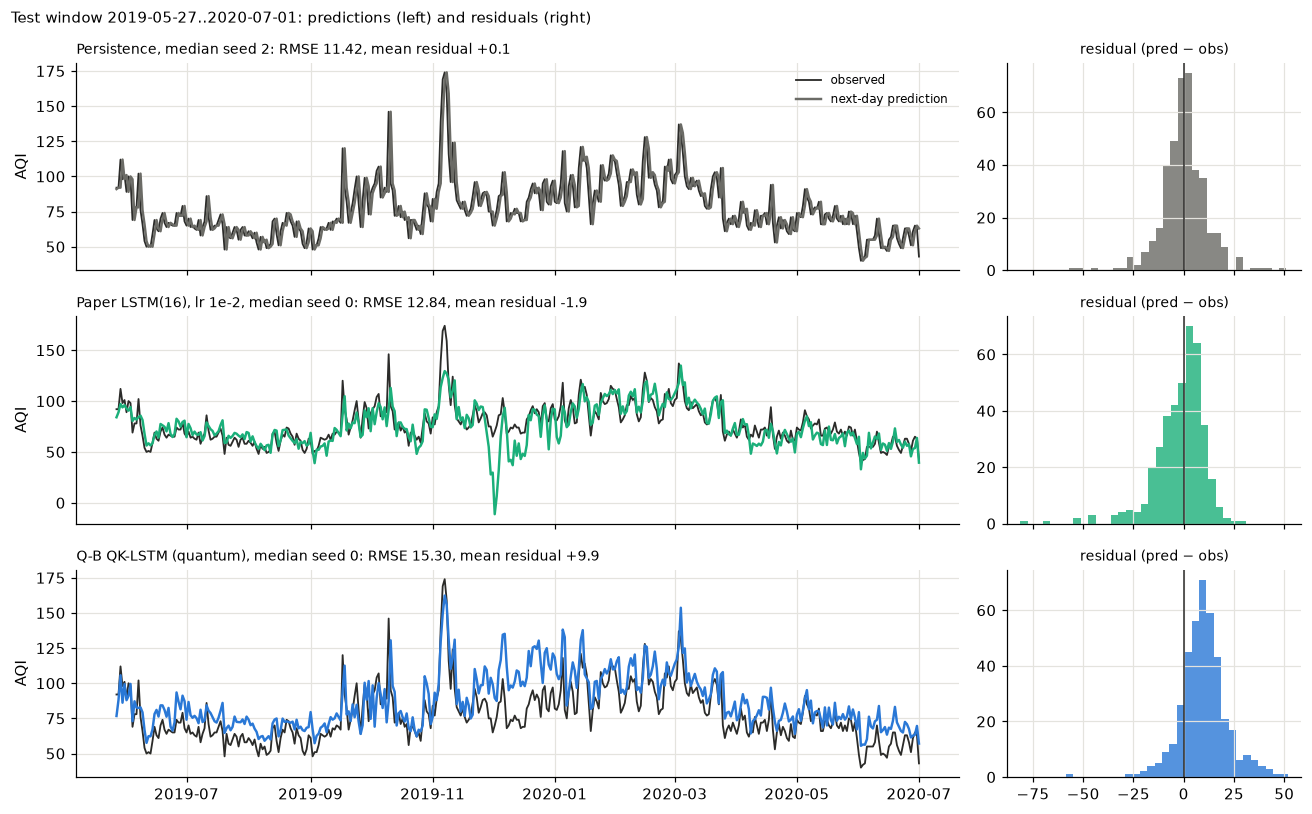

In [20]:
def median_seed(by_seed):
    ordered = sorted(by_seed, key=lambda s: by_seed[s]["rmse"])
    return ordered[len(ordered) // 2]

panels = (("Persistence", tuned["Persistence (0)"], COLORS["naive"]), ("Paper LSTM(16), lr 1e-2", tuned["Paper LSTM(16) (1,873)"], COLORS["lstm"]),
          ("Q-B QK-LSTM (quantum)", qb, COLORS["quantum"]))
fig, axes = plt.subplots(len(panels), 2, figsize=(12, 7.5), gridspec_kw={"width_ratios": [3, 1]}, sharex="col")
for row, (label, runs, color) in enumerate(panels):
    seed = median_seed(runs)
    frame = pd.read_csv(runs[seed]["run_dir"] / "predictions.csv", parse_dates=["date"])
    frame = frame[(frame.split == "test") & frame.target_observed]
    residual = frame.aqi_pred - frame.aqi_true
    axes[row, 0].plot(frame.date, frame.aqi_true, color=COLORS["observed"], lw=1.2, label="observed")
    axes[row, 0].plot(frame.date, frame.aqi_pred, color=color, lw=1.6, label="next-day prediction")
    axes[row, 0].set_title(f"{label}, median seed {seed}: RMSE {runs[seed]['rmse']:.2f}, mean residual {residual.mean():+.1f}", loc="left", fontsize=9)
    axes[row, 0].set_ylabel("AQI")
    axes[row, 1].hist(residual, bins=30, color=color, alpha=0.8); axes[row, 1].axvline(0, color=COLORS["observed"], lw=1)
    axes[row, 1].set_title("residual (pred − obs)", fontsize=9)
axes[0, 0].legend(loc="upper right", frameon=False, fontsize=8)
fig.suptitle("Test window 2019-05-27..2020-07-01: predictions (left) and residuals (right)", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

**Observation.**
- (10a) On the calendar-2020 window every model scores better in absolute terms. No comparison is separated there: QK-LSTM vs the LSTMs and quantum vs RBF all have CIs that include 0. The 80/20 quantum-over-RBF difference does not replicate.
- (10b) Every learned model over-predicts the lower-AQI test period. The kernel models do so most (+7.5 to +8 AQI), then ridge (+6.9) and the tuned LSTMs (about +5); persistence is unbiased (≈ 0).
- The QK-LSTM trace sits visibly above the observations in 2019-12..2020-02, the period where the paper says the *LSTM* mispredicts.

**Inference.**
- Most of the QK-LSTM's extra error is a level bias. The model relies less on the current inputs and more on the training-period level.
- Single-run comparisons (as in the paper) cannot rank these models: per-model seed std is 2–4 RMSE.

**Remaining uncertainty.** Only two test windows and one city are available.

**Claim impact.**
- C1 and C2 are not supported on any window (worse on 80/20, not separated on 2020).
- C3 is not reproduced: the paper's qualitative trace claim is reversed.

### 10c. Fresh seeds 5–9 (independent replication, sweep S7)

Every result so far used seeds 0–4. S7 re-ran the decisive comparisons on seeds **5–9**, which were never used before, with the decision rule recorded in `LOG.md` before launch. QK-LSTM (paper hyperparameters) is compared with the paper's LSTM and the size-matched LSTM, at the paper's learning rate and at the tuned one.

In [21]:
S7 = "s7_fresh_seeds"
fresh = (5, 6, 7, 8, 9)
qb_f = load_runs(S7, "QB_quantum_209", seeds=fresh)
s7_rows = {
    "(a) vs paper LSTM, lr 1e-3": paired(qb_f, load_runs(S7, "B1_lstm_1873", seeds=fresh)),
    "(b) vs LSTM(3), lr 1e-3": paired(qb_f, load_runs(S7, "B2_lstm_matched_196", seeds=fresh)),
    "(c) vs paper LSTM, lr 1e-2": paired(qb_f, load_runs(S7, "B1_lstm16_lr0.01", seeds=fresh)),
    "(d) vs LSTM(3), lr 1e-2": paired(qb_f, load_runs(S7, "B2_lstm3_lr0.01", seeds=fresh)),
}
display(pd.DataFrame(s7_rows).T.astype({"mean": float, "ci_low": float, "ci_high": float}).round(3))
print(f"Q-B QK-LSTM on fresh seeds: RMSE {summary(qb_f)[0]:.2f} ± {summary(qb_f)[1]:.2f} (sample std); per seed {np.round(summary(qb_f)[2], 2).tolist()}")

,mean,ci_low,ci_high,A better on seeds,decision
"(a) vs paper LSTM, lr 1e-3",3.254,0.928,5.581,0/5,A worse
"(b) vs LSTM(3), lr 1e-3",2.304,-0.557,5.165,1/5,not separated
"(c) vs paper LSTM, lr 1e-2",1.992,-0.814,4.797,2/5,not separated
"(d) vs LSTM(3), lr 1e-2",2.677,1.573,3.781,0/5,A worse


Q-B QK-LSTM on fresh seeds: RMSE 15.83 ± 3.39 (sample std); per seed [12.5, 21.5, 15.77, 15.04, 14.32]


**Observation.**
- In all four comparisons QK-LSTM has the higher mean RMSE on the fresh seeds, by 2.0–3.3 AQI, and it is better on at most 2 of 5 seeds.
- Two comparisons are "worse" (95% CI above 0) and two are "not separated".
- A supplementary pooled analysis over all 10 seeds, which was not pre-declared, gives "worse" in all four (`results/s7_fresh_seeds/pooled_seeds_0_9.md`).

**Inference.** "QK-LSTM is not better than the LSTMs" replicates on unseen seeds. Statistical support for "worse" needs more than 5 seeds per comparison, because the seed-to-seed spread is large.

**Claim impact.** C1 and C2 remain unsupported. The strength of the contradiction is partly seed-sensitive at n = 5.

### 10d. Causal preprocessing (sweep S8)

The paper fills gaps by linear interpolation in time (Eq. 3). That uses *later* observations to fill earlier gaps.
- In this data the test inputs have no gaps, and no fill crosses the train/test boundary, so no test information leaks.
- But 712 of 1,604 training windows contain values filled from later days, which can change what a model learns.

S8 re-ran the paper's LSTM, Q-B and its RBF control with **causal** filling (carry the last observation forward). It uses the same seeds 0–4 as S1, so the runs pair by seed with the original-preprocessing runs, and the 402 test days are identical.

In [22]:
S8 = "s8_causal_fill"
rbf_s1 = load_runs(S1, "B3B_rbf_209")
pairs_s8 = {"paper LSTM(16)": (lstm16, load_runs(S8, "B1_lstm_1873_causal")),
            "Q-B quantum": (qb, load_runs(S8, "QB_quantum_209_causal")),
            "Q-B RBF": (rbf_s1, load_runs(S8, "B3B_rbf_209_causal"))}
effect = {name: paired(causal, original) for name, (original, causal) in pairs_s8.items()}
display(pd.DataFrame(effect).T.rename(columns={"A better on seeds": "causal better on seeds"}).astype({"mean": float, "ci_low": float, "ci_high": float}).round(3)
        .rename_axis("RMSE change: causal − original"))
lstm_c, qb_c, rbf_c = (pairs_s8[k][1] for k in ("paper LSTM(16)", "Q-B quantum", "Q-B RBF"))
did = {s: (qb_c[s]["rmse"] - rbf_c[s]["rmse"]) - (qb[s]["rmse"] - rbf_s1[s]["rmse"]) for s in range(5)}
did_runs = {s: {"rmse": v} for s, v in did.items()}
zero = {s: {"rmse": 0.0} for s in range(5)}
s8_rows = {"Q-B quantum − paper LSTM, causal": paired(qb_c, lstm_c),
           "Q-B quantum − RBF, causal": paired(qb_c, rbf_c),
           "difference-in-differences (quantum − RBF), causal − original": paired(did_runs, zero)}
display(pd.DataFrame(s8_rows).T.astype({"mean": float, "ci_low": float, "ci_high": float}).round(3))

,mean,ci_low,ci_high,causal better on seeds,decision
RMSE change: causal − original,,,,,
paper LSTM(16),2.629,1.081,4.176,0/5,A worse
Q-B quantum,0.622,-0.207,1.451,1/5,not separated
Q-B RBF,0.410,-0.640,1.459,2/5,not separated


,mean,ci_low,ci_high,A better on seeds,decision
"Q-B quantum − paper LSTM, causal",1.062,-0.972,3.096,1/5,not separated
"Q-B quantum − RBF, causal",-0.113,-0.576,0.349,4/5,not separated
"difference-in-differences (quantum − RBF), causal − original",0.213,-0.265,0.691,2/5,not separated


**Observation.**
- Causal filling makes the **LSTM clearly worse** (+2.6 RMSE, CI above 0), while QK-LSTM and its RBF control barely change (CIs include 0).
- Under causal preprocessing, QK-LSTM vs the paper's LSTM is **not separated** (it was "worse" with the paper's preprocessing).
- The quantum − RBF difference is unchanged by the preprocessing (the difference-in-differences CI includes 0).

**Inference.** The paper's interpolation benefits the LSTM much more than the kernel models. Part of the LSTM's advantage in §7–§8 depends on that non-causal preprocessing of the training data. Under causal preprocessing every learned model is further behind persistence, which does not use the pollutant inputs.

**Remaining uncertainty.**
- The size-matched LSTM(3) and the tuned learning rates were not re-run with causal preprocessing.
- Values before a column's first observation (series start, training only) are still back-filled.

**Claim impact.**
- C1 stays unsupported: QK-LSTM is better in no setting.
- The stronger statement "QK-LSTM is significantly worse than the LSTM" holds only with the paper's preprocessing.
- C4 stays unsupported.

## 11. Photonic assessment (MerLin adaptation)

This section is an **adaptation**, not part of the paper.

**What must be preserved.** The quantum element of QK-LSTM is a single thing: a fidelity kernel between the learned 4-dimensional compression $z_t$ and fixed references, with no trainable circuit parameters.

**The photonic counterpart.** A linear-optical fidelity kernel
$$k(z_t,z_j)=\big|\langle s|\,U^\dagger(z_j)\,U(z_t)\,|s\rangle\big|^2,\qquad U(z)=M_{\rm out}\,\Phi(z)\,M_{\rm in},$$
with:
- 4 modes;
- 2 indistinguishable photons in $|s\rangle=|1,0,1,0\rangle$;
- fixed (non-trainable, seeded) Mach-Zehnder meshes $M_{\rm in}$ and $M_{\rm out}$;
- one encoding phase per mode, $\Phi(z)$.

The gate wiring, references and parameter counts (209 / 449) are identical to the qubit model. Unlike the paper's text circuit, two-photon interference (matrix permanents) makes this kernel *non-factorising*. That gives the "rich feature space" idea a fairer chance.

**Mappings rejected.**
- Photonic variational gates: they change the method and add parameters.
- A dual-rail copy of the qubit circuit: it would reproduce a kernel that factorises anyway.

A single-photon kernel is run only as an ablation.

In [23]:
import merlin as ml
from lib.qk_lstm_merlin import PhotonicFidelityKernel

photonic = PhotonicFidelityKernel(4, [1, 0, 1, 0], [7, 8])
torch.manual_seed(1)
zp = torch.randn(5, 4, requires_grad=True)
gram_fock = photonic(zp, zp.detach())
print("MerLin", ml.__version__, "| computation space:", photonic.describe()["computation_space"], "| photons:", photonic.n_photons, "| modes:", photonic.n_modes)
print("FOCK kernel: diag == 1:", bool(torch.allclose(torch.diagonal(gram_fock), torch.ones(5), atol=1e-5)),
      "| max |K - K^T| =", f"{float((gram_fock - gram_fock.T).abs().max().detach()):.1e}")
gram_fock.sum().backward()
print("gradient reaches the compressed input z:", bool(zp.grad.abs().sum() > 0), "| trainable circuit parameters:", photonic.describe()["trainable_circuit_parameters"])

unbunched = PhotonicFidelityKernel(4, [1, 0, 1, 0], [7, 8], computation_space="unbunched")
zd = zp.detach()
cross_u, gram_u = unbunched(zd, zd), unbunched.kernel(zd)
print(f"UNBUNCHED cross-kernel: max |K - K^T| = {float((cross_u - cross_u.T).abs().max()):.3f} (asymmetric)")
print(f"UNBUNCHED Gram path: symmetric, but max |K - K_fock| = {float((gram_u - photonic.kernel(zd)).abs().max()):.3f} (renormalised)")

MerLin 0.4.1 | computation space: FOCK | photons: 2 | modes: 4
FOCK kernel: diag == 1: True | max |K - K^T| = 1.2e-07
gradient reaches the compressed input z: True | trainable circuit parameters: 0
UNBUNCHED cross-kernel: max |K - K^T| = 0.011 (asymmetric)
UNBUNCHED Gram path: symmetric, but max |K - K_fock| = 0.180 (renormalised)


The last two lines explain a design choice. In MerLin 0.4.1, the `UNBUNCHED` computation space renormalises the kernel by the probability of collision-free outcomes, so it is not the fidelity of the paper's Eq. 7. The cross-kernel is also asymmetric.
- The adaptation therefore computes in `FOCK` space.
- For a collision-free input state, that equals what threshold detectors would measure *without* postselection. The detector model is still threshold detection.
- This is reported to the MerLin team in `ACTION_REQUIRED_SEND_TO_MERLIN_TEAM.md`.

**Stored evidence: sweep S6.** The photonic Q-B and Q-A, plus the 1-photon ablation, ran at the paper's hyperparameters on the 80/20 split with seeds 0–4. They are paired with the qubit runs of S1 (same initial weights and references).

In [24]:
S6 = "s6_merlin"
qb_ph, qa_ph, qb_1ph = load_runs(S6, "QB_photonic_2ph_209"), load_runs(S6, "QA_photonic_2ph_eq6_N4"), load_runs(S6, "QB_photonic_1ph_ablation")
photonic_table = {
    "Q-B qubit kernel (S1)": qb, "Q-B photonic, 2 photons": qb_ph, "Q-B photonic, 1 photon (ablation)": qb_1ph,
    "Q-A qubit kernel (S1)": qa, "Q-A photonic, 2 photons": qa_ph,
    "Q-B RBF control (S1)": tuned["Q-B RBF control (209)"], "paper LSTM (S1)": lstm16, "LSTM(3) (S1)": load_runs(S1, "B2_lstm_matched_196"),
}
photonic_summary = pd.DataFrame({n: {"RMSE mean": round(summary(r)[0], 3), "RMSE std": round(summary(r)[1], 3), "R² mean": round(summary(r, "r2")[0], 3),
                                     "per-seed RMSE": np.round(summary(r)[2], 2).tolist()} for n, r in photonic_table.items()}).T
display(photonic_summary)
TOLERANCE = 1.0  # predeclared: photonic preserves the qubit behaviour if the paired 95% CI lies within ±1.0 RMSE
comp = pd.DataFrame([paired(qb_ph, qb), paired(qa_ph, qa), paired(qb_ph, qb_1ph), paired(qb_ph, photonic_table["Q-B RBF control (S1)"]),
                     paired(qb_ph, lstm16), paired(qb_ph, photonic_table["LSTM(3) (S1)"])],
                    index=["Q-B photonic − qubit", "Q-A photonic − qubit", "2 photons − 1 photon", "photonic − RBF", "photonic − paper LSTM", "photonic − LSTM(3)"])
preservation_rows = ["Q-B photonic − qubit", "Q-A photonic − qubit"]
comp["preserved (CI within ±1.0)"] = ""
comp.loc[preservation_rows, "preserved (CI within ±1.0)"] = ((comp.ci_low >= -TOLERANCE) & (comp.ci_high <= TOLERANCE))[preservation_rows].map({True: "yes", False: "no"})
display(comp.round(3))

,RMSE mean,RMSE std,R² mean,per-seed RMSE
Q-B qubit kernel (S1),15.679,3.965,0.327,"[15.3, 19.19, 20.24, 11.78, 11.88]"
"Q-B photonic, 2 photons",15.728,3.722,0.327,"[15.17, 18.62, 20.4, 12.66, 11.79]"
"Q-B photonic, 1 photon (ablation)",15.524,3.98,0.339,"[13.87, 19.31, 20.27, 12.13, 12.04]"
Q-A qubit kernel (S1),15.661,3.771,0.332,"[14.83, 18.98, 20.19, 12.33, 11.97]"
"Q-A photonic, 2 photons",15.737,4.073,0.32,"[14.79, 19.56, 20.4, 12.55, 11.39]"
Q-B RBF control (S1),16.006,3.801,0.303,"[15.56, 19.33, 20.45, 12.47, 12.22]"
paper LSTM (S1),12.611,2.661,0.571,"[11.02, 14.2, 16.49, 11.3, 10.05]"
LSTM(3) (S1),13.351,3.615,0.509,"[12.28, 16.39, 17.89, 10.06, 10.13]"


,mean,ci_low,ci_high,A better on seeds,decision,preserved (CI within ±1.0)
Q-B photonic − qubit,0.049,-0.616,0.713,3/5,not separated,yes
Q-A photonic − qubit,0.076,-0.459,0.612,2/5,not separated,yes
2 photons − 1 photon,0.204,-0.746,1.154,2/5,not separated,
photonic − RBF,-0.278,-0.720,0.165,4/5,not separated,
photonic − paper LSTM,3.117,1.321,4.912,0/5,A worse,
photonic − LSTM(3),2.377,1.801,2.954,0/5,A worse,


In [25]:
hardware = pd.DataFrame([
    {"configuration": cfg_name, "computation space": "FOCK (computation)", "detector model": "threshold-equivalent (collision-free input; no PNR)",
     "photons": n_ph, "modes": 4, "input state": state, "encoding": "angle, 1 phase/mode, scale 1; fixed MZI meshes seeds 7/8",
     "measurement": "return-to-input probability", "postselection": "none", "simulator / QPU": f"MerLin {ml.__version__} SLOS, analytic",
     "shots": 0, "wall-clock / run (min)": round(wall_minutes(runs), 1), "seeds": "0-4"}
    for cfg_name, n_ph, state, runs in (("Q-B photonic (209)", 2, "|1,0,1,0>", qb_ph), ("Q-A photonic (449)", 2, "|1,0,1,0>", qa_ph), ("Q-B 1-photon ablation", 1, "|1,0,0,0>", qb_1ph))
]).set_index("configuration")
display(hardware)

,computation space,detector model,photons,modes,input state,encoding,measurement,postselection,simulator / QPU,shots,wall-clock / run (min),seeds
configuration,,,,,,,,,,,,
Q-B photonic (209),FOCK (computation),threshold-equivalent (collision-free input; no...,2,4,"|1,0,1,0>","angle, 1 phase/mode, scale 1; fixed MZI meshes...",return-to-input probability,none,"MerLin 0.4.1 SLOS, analytic",0,6.2,0-4
Q-A photonic (449),FOCK (computation),threshold-equivalent (collision-free input; no...,2,4,"|1,0,1,0>","angle, 1 phase/mode, scale 1; fixed MZI meshes...",return-to-input probability,none,"MerLin 0.4.1 SLOS, analytic",0,5.7,0-4
Q-B 1-photon ablation,FOCK (computation),threshold-equivalent (collision-free input; no...,1,4,"|1,0,0,0>","angle, 1 phase/mode, scale 1; fixed MZI meshes...",return-to-input probability,none,"MerLin 0.4.1 SLOS, analytic",0,5.2,0-4


**Observation.**
- The photonic kernel reproduces the qubit QK-LSTM almost exactly: the paired CIs for Q-B and Q-A lie inside the predeclared ±1.0 tolerance.
- Two photons are not separated from one photon.
- The photonic model is not separated from the RBF control either.
- It is worse than both LSTMs on 5/5 seeds.

**Inference.**
- The mapping preserves the method's behaviour faithfully.
- Genuine multi-photon interference, which a classical product kernel cannot express, does not help this task.
- The similarity function is not the bottleneck.

**Remaining uncertainty.**
- Ideal simulation only: no loss, partial distinguishability or shot noise.
- One fixed random feature map, at 2 photons / 4 modes.
- The 2020 split and the tuning grid were not repeated for the photonic kernel. Phase 3 showed neither changes the kernel models' ranking.

**Claim impact.** The paper's claimed advantage does not appear in the photonic modality either. Photonic verdict: *faithful adaptation, no advantage*.

## 12. Claim-level conclusion

The cell below re-derives the decisive numbers from the objects loaded above. It asserts the direction of every conclusion stated afterwards, so the text cannot drift from the evidence.

In [26]:
decisive = {
    "C1: Q-B QK-LSTM − paper LSTM (tuned)": paired(qb, tuned["Paper LSTM(16) (1,873)"]),
    "C1: Q-B QK-LSTM − paper LSTM (paper hp)": paired(qb, lstm16),
    "C2: Q-B QK-LSTM − LSTM(3) (tuned)": paired(qb, tuned["LSTM(3) size-matched (196)"]),
    "C4: Q-B quantum − RBF, 80/20": paired(qb, tuned["Q-B RBF control (209)"]),
    "C4: Q-B quantum − RBF, 2020": paired(s2["Q-B QK-LSTM"], s2["Q-B RBF"]),
    "C1 on 2020: Q-B − paper LSTM": paired(s2["Q-B QK-LSTM"], s2["paper LSTM"]),
    "Photonic − qubit (Q-B)": paired(qb_ph, qb),
    "C1 fresh seeds 5-9: Q-B − paper LSTM (lr 1e-3)": s7_rows["(a) vs paper LSTM, lr 1e-3"],
    "C1 causal preprocessing: Q-B − paper LSTM": s8_rows["Q-B quantum − paper LSTM, causal"],
}
decisive_table = pd.DataFrame(decisive).T
for col in ("mean", "ci_low", "ci_high"):
    decisive_table[col] = decisive_table[col].astype(float).round(3)
display(decisive_table)
assert decisive["C1: Q-B QK-LSTM − paper LSTM (tuned)"]["decision"] == "A worse"
assert decisive["C1: Q-B QK-LSTM − paper LSTM (paper hp)"]["decision"] == "A worse"
assert decisive["C2: Q-B QK-LSTM − LSTM(3) (tuned)"]["decision"] == "A worse"
assert decisive["C4: Q-B quantum − RBF, 2020"]["decision"] == "not separated"
assert decisive["C1 on 2020: Q-B − paper LSTM"]["decision"] == "not separated"
assert -TOLERANCE <= decisive["Photonic − qubit (Q-B)"]["ci_low"] and decisive["Photonic − qubit (Q-B)"]["ci_high"] <= TOLERANCE
# QK-LSTM is better in no comparison; "worse" is preprocessing-dependent.
assert all(row["decision"] != "A better" for name, row in decisive.items() if "C1" in name or "C2" in name)
assert all(row["mean"] > 0 for row in s7_rows.values())
assert decisive["C1 causal preprocessing: Q-B − paper LSTM"]["decision"] == "not separated"
assert s8_rows["difference-in-differences (quantum − RBF), causal − original"]["decision"] == "not separated"
print("All conclusion directions verified against the loaded evidence.")

,mean,ci_low,ci_high,A better on seeds,decision
C1: Q-B QK-LSTM − paper LSTM (tuned),2.797,0.496,5.098,0/5,A worse
C1: Q-B QK-LSTM − paper LSTM (paper hp),3.068,0.757,5.379,0/5,A worse
C2: Q-B QK-LSTM − LSTM(3) (tuned),3.963,1.372,6.554,0/5,A worse
"C4: Q-B quantum − RBF, 80/20",-0.326,-0.591,-0.062,5/5,A better
"C4: Q-B quantum − RBF, 2020",-0.009,-0.375,0.357,2/5,not separated
C1 on 2020: Q-B − paper LSTM,0.993,-1.251,3.238,2/5,not separated
Photonic − qubit (Q-B),0.049,-0.616,0.713,3/5,not separated
C1 fresh seeds 5-9: Q-B − paper LSTM (lr 1e-3),3.254,0.928,5.581,0/5,A worse
C1 causal preprocessing: Q-B − paper LSTM,1.062,-0.972,3.096,1/5,not separated


All conclusion directions verified against the loaded evidence.


### Five separate questions

| Question | Answer | Evidence |
|---|---|---|
| Does the software execute? | **Yes.** Live runs complete through the real runner, and 43 unit tests pass. | §4, §6 |
| Does the method solve the task? | **Partly.** QK-LSTM learns (R² ≈ 0.33, known-answer R² ≈ 0.996) but does not beat persistence. | §7, §9c |
| Does the paper's metric reproduce? | **No.** RMSE 15.7 ± 4.0 vs 9.20. The paper's own Table I is internally inconsistent. | §7 |
| Does the paper's explanation survive controls? | **No.** A classical RBF kernel or a photonic kernel gives the same result within ≈ 0.3 RMSE, and the text circuit factorises. | §4, §9, §11 |
| Does the method beat a fair baseline? | **No, in no setting.** With the paper's preprocessing it is worse than the paper's LSTM and a size-matched LSTM on 5/5 seeds (80/20), and still higher-error on fresh seeds 5–9. It is not separated on the 2020 window, and not separated from the paper's LSTM under causal preprocessing. | §8, §10 |

### Limitations

- **Data.** The data is a Kaggle compilation of CPCB data, whose identity with the paper's copy is inferred, not confirmed.
- **Protocol.** The split, horizon, angle map, number of references, optimizer and outlier handling are documented assumptions; the paper does not state them.
- **Architecture.** Two architecture readings were run (Q-A per Eq. 6, Q-B per the parameter count), and they agree. The exact architecture the authors ran is unknown.
- **Scope.** Two test windows and one city.
- **Uncertainty.** The paired CIs use n = 5 seeds and are approximate. The seed-to-seed spread is large (RMSE sample std 2–4); on fresh seeds two of four decisive comparisons are not separated (§10c).
- **Preprocessing.** The main results use the paper's two-sided interpolation. In this data that means no future-dependent interpolation in test inputs and no interpolation across the train/test boundary, but 712 training windows contain values filled from later days. Causal preprocessing removes the LSTM's significant advantage (§10d). The size-matched LSTM and the tuned learning rates were not re-run causally.
- **Untuned control.** The RBF bandwidth γ was not tuned, which limits the strength of the kernel-attribution statement (C4).
- **Partially matched baseline.** Persistence uses past AQI, which the learned models do not take as input. It is a naive floor, not a matched control.
- **Smoke-scale live cells.** The live cells in §6 are a smoke budget (3 epochs, 1 seed) and support no claim. Every claim rests on the stored 20-epoch, 5-seed runs, which are recomputed in this notebook from their artifacts.
- **Photonic results.** Ideal simulation only (no loss, distinguishability or shot noise), with one fixed random feature map at 2 photons / 4 modes. The 2020 split and the tuning grid were not repeated for the photonic kernel.
- **Diagnostic sweep.** S5 is a partial sweep (6 attempt-1 failures, superseded by S5b/S5c). It is a diagnostic and enters no claim.
- **Wall-clock.** Times are descriptive only (some runs shared the CPU). No speed claim is made.

### Conclusions

1. **What reproduced.**
   - The parameter counts of Table II are exact: 209 for QK-LSTM, 1,873 for the LSTM (§4).
   - The pipeline is correct: known-answer test, kernel identities, and autograd = parameter-shift (§4, §9c).
2. **What did not reproduce.**
   - The Table I metric values: QK-LSTM RMSE 15.7 vs 9.20, R² 0.33 vs 0.84 (§7).
   - The model ranking: QK-LSTM is not better than the LSTM anywhere. With the paper's preprocessing the LSTM is significantly better (§7, §8); with causal preprocessing they are not separated (§10d).
   - The qualitative claim of Fig. 3: our QK-LSTM, not our LSTM, is biased in 2019-12..2020-02 (§10b).
3. **What remains unresolved.**
   - The paper's exact protocol (horizon, split, data copy, architecture). Its Table I is inconsistent with its own metric definitions, so the cause of the gap cannot be pinned down without the authors' code (§7, §9c).
   - Whether the small quantum-over-RBF difference on the 80/20 window (−0.33 RMSE) is a bandwidth effect: γ was untuned, and the difference does not replicate on 2020, on validation or under causal preprocessing (§9a, §9b, §10a, §10d).
   - How large QK-LSTM's deficit to the LSTMs really is: significant with the paper's preprocessing and seeds 0–4, partly seed-sensitive (§10c), and not significant under causal preprocessing (§10d).
4. **What was not attempted.**
   - Hardware execution.
   - The block-encoding, tensor-network and distributed scalability claims of Sec. V, for which the paper has no experiments.
   - Other cities or datasets.
5. **Reproduction verdict: not reproduced.**
   - C1 (accuracy) is **unsupported**: QK-LSTM is better than the LSTM in no setting. It is significantly worse only with the paper's preprocessing (§8, §10a, §10c, §10d).
   - C2 (compactness) is **unsupported**: the parameter count reproduces, but a size-matched LSTM is more accurate with the paper's preprocessing (§8). This was not re-tested causally.
   - C3 is **not reproduced** (§10b).
   - C4 (quantum kernel as the source of a gain) is **unsupported**: there is no gain over classical models, and kernel swaps barely move the result (§9, §11).
6. **Photonic verdict: faithful adaptation, no advantage.**
   - A 2-photon MerLin fidelity kernel preserves QK-LSTM behaviour within the predeclared ±1.0 RMSE tolerance.
   - Multi-photon interference gives no measurable benefit.
   - The photonic QK-LSTM remains worse than both LSTMs (§11).
   - A MerLin issue was found: the `UNBUNCHED` fidelity kernel is renormalised (§11).